# Anatomy of a Redemption
### Spark-Based Multi-Source Sentiment Analysis of Cyberpunk 2077

Lab Group 1 — Data Processing 2, SS 2026

Batch pipeline: Reddit comments + Steam reviews over the 34-month window
(Dec 2020 – Dec 2023), sentiment via VADER, aligned against a patch timeline.
**Core thesis:** Reddit recovers faster than Steam.

**Stages:** 0 Config · 1 Ingest+Filter · 2 Cleaning · 3 VADER · 4 Aggregation · 5 Analysis/Plots

> Final, aggregated results go to `results/` (small, in the repo). The report is written from
> these files, not by re-running the pipeline.

## 0 · Configuration & Parameters (central)

All settings in **one block** — prerequisite for reproducibility. `DATA_MODE`
is the only switch between sample (development) and full run (`results/` snapshot). `SEED`
covers everything stochastic (especially LDA).

In [1]:
import findspark
findspark.init()

from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# ===== Central parameters (one block — reproducibility) =====
# DATA_MODE switches between the small sample (fast iteration) and the full run
# (the `results/` snapshot). The sample is carved once from data/raw/ by the
# "0b · Carve sample" cell below; after that, "sample" runs in seconds.
# Switch to "full" for the final results snapshot.
DATA_MODE = "sample"           # "sample" | "full"
SEED = 42                       # for everything stochastic (esp. LDA setSeed)
assert DATA_MODE in ("sample", "full")

WINDOW_START = "2020-12-01"     # 34-month window, inclusive bounds
WINDOW_END   = "2023-12-31"
SUBREDDITS   = ["cyberpunkgame", "LowSodiumCyberpunk", "Games", "pcgaming"]
STEAM_APP_ID = 1091500          # Cyberpunk 2077

SAMPLE_PER_FILE = 5000          # records kept per raw file when carving the sample
ANOMALY_Z_THRESHOLD = 3.0       # volume anomaly / review-bombing flag
LDA_NUM_TOPICS = 8              # topic analysis

# ===== Resolve project root robustly (cross-platform: macOS + Windows) =====
# Notebooks have no __file__; the Jupyter CWD is sometimes the project root and
# sometimes notebooks/. So we walk up from the CWD to find the project root.
def _find_project_root(start: Path) -> Path:
    for p in (start, *start.parents):
        if (p / "notebooks").is_dir() and (p / "README.md").exists():
            return p
    return start

PROJECT_ROOT = _find_project_root(Path.cwd().resolve())

# ===== Paths (POSIX strings -> accepted by Spark on macOS AND Windows) =====
_SUB           = "sample" if DATA_MODE == "sample" else "raw"
RAW_REDDIT     = (PROJECT_ROOT / "data" / _SUB / "reddit").as_posix() + "/"
RAW_STEAM      = (PROJECT_ROOT / "data" / _SUB / "steam").as_posix() + "/"
PROCESSED      = (PROJECT_ROOT / "data" / "processed").as_posix() + "/"
RESULTS        = (PROJECT_ROOT / "results").as_posix() + "/"
FIGURES        = (PROJECT_ROOT / "results" / "figures").as_posix() + "/"
# Patch timeline: small + hand-maintained -> lives in the repo (data/sample/), for sample AND full
PATCH_TIMELINE = (PROJECT_ROOT / "data" / "sample" / "patch_timeline.csv").as_posix()
Path(RESULTS).mkdir(exist_ok=True)
Path(FIGURES).mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"DATA_MODE={DATA_MODE}  window={WINDOW_START}..{WINDOW_END}  seed={SEED}")

PROJECT_ROOT = C:\Github\Data-Processing-2-
DATA_MODE=sample  window=2020-12-01..2023-12-31  seed=42


### 0b · Carve a small sample (one-time, idempotent)

To follow the workflow rule *"develop on the sample, run the full set only once"*, we carve a
small slice of the raw data into `data/sample/`. The carve writes the **same raw formats** the
full pipeline expects — Reddit as `*.jsonl` (verbatim lines), Steam as CSV — so every cell below
runs **unchanged** on the sample (the "scales sample → full" requirement).

- Reads from `data/raw/` regardless of `DATA_MODE`; **skipped** if the sample already exists or
  the raw dumps are absent (so it is safe to leave in the notebook).
- Keeps the first `SAMPLE_PER_FILE` in-window records per file. Reddit/Steam dumps are ordered by
  time, so the sample covers the **launch window** (Dec 2020) — enough to exercise every code path
  fast. The full 34-month spread comes from `DATA_MODE = "full"`.

In [2]:
# -------------------------------------------------------------
# Carve data/sample/{reddit,steam}/ from data/raw/ (one-time, idempotent).
# Pure Python (no Spark): stream the raw dumps and stop early after
# SAMPLE_PER_FILE in-window records, so it is fast even on the big dumps.
# -------------------------------------------------------------
import csv, io, json, datetime as _dt
import zstandard

_raw_reddit = PROJECT_ROOT / "data" / "raw" / "reddit"
_raw_steam  = PROJECT_ROOT / "data" / "raw" / "steam"
_smp_reddit = PROJECT_ROOT / "data" / "sample" / "reddit"
_smp_steam  = PROJECT_ROOT / "data" / "sample" / "steam"

# Window bounds as epoch seconds, to filter the raw reddit `created_utc`.
_WIN_START_TS = int(_dt.datetime.fromisoformat(WINDOW_START).replace(tzinfo=_dt.timezone.utc).timestamp())
_WIN_END_TS   = int(_dt.datetime.fromisoformat(WINDOW_END).replace(tzinfo=_dt.timezone.utc).timestamp()) + 86400

def _carve_reddit():
    _smp_reddit.mkdir(parents=True, exist_ok=True)
    for zst in sorted(_raw_reddit.glob("*.zst")):
        out = _smp_reddit / (zst.stem + ".jsonl")        # e.g. cyberpunkgame_comments.jsonl
        if out.exists() and out.stat().st_size > 0:
            print("skip (exists):", out.name); continue
        kept = 0
        dctx = zstandard.ZstdDecompressor(max_window_size=2**31)
        with open(zst, "rb") as fin, dctx.stream_reader(fin) as raw, \
             io.TextIOWrapper(raw, encoding="utf-8", errors="ignore") as text, \
             open(out, "w", encoding="utf-8") as fout:
            for line in text:
                try:
                    obj = json.loads(line)
                    ts = int(float(obj.get("created_utc", 0)))
                except (ValueError, TypeError):
                    continue
                if obj.get("subreddit") in SUBREDDITS and _WIN_START_TS <= ts < _WIN_END_TS:
                    fout.write(line if line.endswith("\n") else line + "\n")
                    kept += 1
                    if kept >= SAMPLE_PER_FILE:
                        break
        print(f"sample reddit: {out.name}  ({kept} records)")

def _carve_steam():
    _smp_steam.mkdir(parents=True, exist_ok=True)
    src = next(iter(sorted(_raw_steam.glob("*.csv"))), None)
    if src is None:
        print("no raw steam csv found — skipping"); return
    out = _smp_steam / src.name
    if out.exists() and out.stat().st_size > 0:
        print("skip (exists):", out.name); return
    kept = 0
    with open(src, "r", encoding="utf-8", newline="") as fin, \
         open(out, "w", encoding="utf-8", newline="") as fout:
        reader, writer = csv.reader(fin), csv.writer(fout)
        writer.writerow(next(reader))                    # header (proper CSV parsing handles quoted newlines)
        for row in reader:
            writer.writerow(row); kept += 1
            if kept >= SAMPLE_PER_FILE:
                break
    print(f"sample steam:  {out.name}  ({kept} rows)")

if _raw_reddit.exists():
    _carve_reddit()
if _raw_steam.exists():
    _carve_steam()
print("Sample ready under data/sample/  — set DATA_MODE='sample' in the config cell to use it.")

skip (exists): cyberpunkgame_comments.jsonl
skip (exists): cyberpunkgame_submissions.jsonl
skip (exists): Games_comments.jsonl
skip (exists): Games_submissions.jsonl
skip (exists): LowSodiumCyberpunk_comments.jsonl
skip (exists): LowSodiumCyberpunk_submissions.jsonl
skip (exists): pcgaming_comments.jsonl
skip (exists): pcgaming_submissions.jsonl
skip (exists): Cyberpunk_2077_Steam_Reviews.csv
Sample ready under data/sample/  — set DATA_MODE='sample' in the config cell to use it.


### SparkSession
Local, `local[*]`. Driver RAM increased for the `full` run.

In [3]:
import os, sys

# Help the kernel find Java + the matching Python (no-op if already set).
# Spark needs JAVA_HOME; on macOS Homebrew installs it in a predictable place.
if not os.environ.get("JAVA_HOME"):
    for _jh in ("/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home",
                "/usr/local/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"):
        if Path(_jh).exists():
            os.environ["JAVA_HOME"] = _jh
            break
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
# Force loopback for the driver. Without this, Spark builds its RPC URL from the
# machine hostname; if that hostname contains an underscore (common on Windows,
# e.g. "Lucas_PC"), Spark rejects it with "Invalid Spark URL". Harmless elsewhere.
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("CyberpunkSentiment")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.driver.host", "127.0.0.1")               # see SPARK_LOCAL_IP note above
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.shuffle.partitions", "200")          # increase for full run if needed
    .config("spark.driver.memory", "8g" if DATA_MODE == "sample" else "12g")
    .config("spark.sql.files.maxPartitionBytes", "128m")    # controls partition size
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark

## 1 · Ingest + Immediate Filter

**Hard rule:** filter immediately on read (subreddits + time window), before anything else.
GB/month should become a fraction early.

Three inputs, unified to a common schema `source, month, date, text`:
- **Reddit comments** (`body`) + **submissions** (`title` + `selftext`) — both included.
- **Steam reviews** — verified schema (`Review`, `Date Posted`).
- Patch timeline (below) is a small side input, not part of the document corpus.

> All **four** subreddits are ingested (r/cyberpunkgame, r/LowSodiumCyberpunk, r/Games, r/pcgaming);
> the design scales to any number of dumps dropped into the same folder.

### 1a · Decompress Reddit dumps (`.zst` → `.jsonl`)

The pip PySpark build ships Hadoop **without the native zstd codec**, so Spark cannot read `.zst`
directly. We decompress once to `.jsonl` (cross-platform via the `zstandard` package; cached —
skipped if already present). The `.jsonl` are written next to the dumps under the same folder
(git-ignored). Note: the decompressed files are large (~15 GB for the comments dump).

In [4]:
import zstandard

def ensure_jsonl(zst_path: Path) -> Path:
    """Decompress a .zst dump to .jsonl once (idempotent; skipped if present)."""
    out = zst_path.with_suffix(".jsonl")
    if out.exists() and out.stat().st_size > 0:
        return out
    print("decompressing", zst_path.name, "...")
    dctx = zstandard.ZstdDecompressor(max_window_size=2**31)   # dumps use a long window
    with open(zst_path, "rb") as fin, open(out, "wb") as fout:
        dctx.copy_stream(fin, fout, read_size=2**24, write_size=2**24)
    return out

for _zst in sorted(Path(RAW_REDDIT).glob("*.zst")):
    print("ready:", ensure_jsonl(_zst).name)

In [5]:
# -------------------------------------------------------------
# Reddit: comments (body) + submissions (title + selftext), unified.
# Reads the decompressed *.jsonl from the previous cell. Explicit schema
# avoids slow inference over GBs. created_utc may be "123" or "123.0"
# (float string) -> cast double then long.
# -------------------------------------------------------------
from pyspark.sql import types as T

START = F.unix_timestamp(F.lit(WINDOW_START), "yyyy-MM-dd")
END   = F.unix_timestamp(F.lit(WINDOW_END),   "yyyy-MM-dd") + F.lit(86400)   # include the last day

_comment_schema = T.StructType([
    T.StructField("subreddit",   T.StringType()),
    T.StructField("body",        T.StringType()),
    T.StructField("created_utc", T.StringType()),
])
_submission_schema = T.StructType([
    T.StructField("subreddit",   T.StringType()),
    T.StructField("title",       T.StringType()),
    T.StructField("selftext",    T.StringType()),
    T.StructField("created_utc", T.StringType()),
])

def _in_window(df):
    df = df.withColumn("created_utc", F.col("created_utc").cast("double").cast("long"))
    return df.filter(
        F.col("subreddit").isin(SUBREDDITS)            # safety net; design scales to all 4 subreddits
        & (F.col("created_utc") >= START) & (F.col("created_utc") < END)
    )

comments = (
    _in_window(spark.read.schema(_comment_schema).option("pathGlobFilter", "*_comments.jsonl").json(RAW_REDDIT))
    .select("created_utc", F.col("body").alias("text"))
)
submissions = (
    _in_window(spark.read.schema(_submission_schema).option("pathGlobFilter", "*_submissions.jsonl").json(RAW_REDDIT))
    .select("created_utc", F.concat_ws(" ", F.col("title"), F.col("selftext")).alias("text"))
)

reddit = (
    comments.unionByName(submissions)
    .filter(F.col("text").isNotNull() & ~F.trim("text").isin("", "[deleted]", "[removed]"))
    .withColumn("date",  F.to_date(F.from_unixtime("created_utc")))
    .withColumn("month", F.date_format("date", "yyyy-MM"))
    .withColumn("source", F.lit("reddit"))
    .select("source", "month", "date", "text")
)
reddit.show(3, truncate=80)   # cheap peek; full counts come after the write below

+------+-------+----------+-----------------------------------+
|source|  month|      date|                               text|
+------+-------+----------+-----------------------------------+
|reddit|2020-12|2020-12-01|              First world problems.|
|reddit|2020-12|2020-12-01|This post did. Mortally wounded me.|
|reddit|2020-12|2020-12-01|   *Shortages of digital editions?*|
+------+-------+----------+-----------------------------------+
only showing top 3 rows


In [6]:
# -------------------------------------------------------------
# Steam reviews (CSV). Verified schema:
#   ReviewID, SteamID, Rating, Review, "Date Posted", Hours Played, ...
# multiLine + escape='"' because reviews contain newlines and doubled quotes.
# "Date Posted" has TWO formats in this dataset: mostly M/d/yyyy (e.g. 12/9/2020),
# a minority d-MMM-yy (e.g. 8-Aug-24). try_to_timestamp returns NULL on mismatch
# (Spark 4 is strict/ANSI), so we coalesce both patterns; anything else -> NULL -> dropped.
# (Rating = Recommended/Not Recommended kept aside for later VADER validation.)
# -------------------------------------------------------------
_date_expr = (
    "coalesce("
    " to_date(try_to_timestamp(`Date Posted`, 'M/d/yyyy')),"
    " to_date(try_to_timestamp(`Date Posted`, 'd-MMM-yy'))"
    ")"
)
steam = (
    spark.read
    .option("header", True).option("multiLine", True).option("escape", '"')
    .csv(RAW_STEAM)
    .select(F.col("Review").alias("text"), F.expr(_date_expr).alias("date"))
    .filter(F.col("text").isNotNull() & (F.length(F.trim("text")) > 0))
    .filter(F.col("date").between(WINDOW_START, WINDOW_END))   # drops out-of-window (e.g. 2024) + unparsable dates
    .withColumn("month", F.date_format("date", "yyyy-MM"))
    .withColumn("source", F.lit("steam"))
    .select("source", "month", "date", "text")
)
steam.show(3, truncate=80)   # cheap peek; full counts come after the write below

+------+-------+----------+---------------------------------------------------------------------------------------------------------------------------------+
|source|  month|      date|                                                                                                                             text|
+------+-------+----------+---------------------------------------------------------------------------------------------------------------------------------+
| steam|2020-12|2020-12-09|                                                 \n\t\t\t\t\t"Hᴇ's ғᴜᴄᴋᴇᴅ ɪɴ ᴛʜᴇ ʜᴇᴀᴅ, ᴛʜᴇ ᴡᴏʀʟᴅ's ғᴜᴄᴋᴇᴅ ɪɴ ᴛʜᴇ ʜᴇᴀᴅ - ᴀɴᴅ ʏᴏ...|
| steam|2020-12|2020-12-09|                                                  \n\t\t\t\t\tIt's a city of dreams... and I'm a big dreamer.\t\t\t\t\t\n\t\t\t\t|
| steam|2020-12|2020-12-09|\n\t\t\t\t\t======赛博朋克2077======千呼万唤始出来，赛博朋克终问世；夜城诱惑惹人厌，风流轶事留民间；义肢持枪逞英雄，惩恶扬善辨...|
+------+-------+----------+--------------------------------------------------------------------------

In [7]:
# -------------------------------------------------------------
# Combine both sources and persist (partitioned by source + month).
# The write is the one heavy pass; read the small parquet back for stats
# so we don't re-scan the raw data just to count.
# Continue downstream with: spark.read.parquet(PROCESSED + "cleaned/")
# NEVER .collect()/.toPandas() on the full df — aggregate first.
# -------------------------------------------------------------
documents = reddit.unionByName(steam)
(
    documents.write.mode("overwrite")
    .partitionBy("source", "month")
    .parquet(PROCESSED + "cleaned/")
)
print("Written to:", PROCESSED + "cleaned/")

cleaned = spark.read.parquet(PROCESSED + "cleaned/")
cleaned.groupBy("source").count().orderBy("source").show()
print("Total documents:", cleaned.count())

Written to: C:/Github/Data-Processing-2-/data/processed/cleaned/


+------+-----+
|source|count|
+------+-----+
|reddit|38310|
| steam| 5000|
+------+-----+

Total documents: 43310


### 1c · Patch Timeline (3rd Data Source)

Small, manually maintained table (`patch_name, release_date, platform, notes`) with the major
Cyberpunk 2077 patches in the window (1.0 Launch … 2.1). Stored in the repo under `data/sample/`.
Used later as patch markers on the sentiment time series and as anchor for the recovery metric.

In [8]:
# -------------------------------------------------------------
# Read Patch Timeline (3rd data source)
#   Small + manually maintained -> in the repo. Used later for
#   patch markers and the recovery metric (core thesis).
# -------------------------------------------------------------
patches = (
    spark.read.option("header", True).csv(PATCH_TIMELINE)
    .withColumn("release_date", F.to_date("release_date"))
    .withColumn("month", F.date_format("release_date", "yyyy-MM"))
    .filter(F.col("release_date").between(WINDOW_START, WINDOW_END))
)
patches.orderBy("release_date").show(truncate=False)

+-----------------+------------+-------------+------------------------------------------------------------------------+-------+
|patch_name       |release_date|platform     |notes                                                                   |month  |
+-----------------+------------+-------------+------------------------------------------------------------------------+-------+
|1.0 (Launch)     |2020-12-10  |all          |Release; heavy bug/performance backlash, PS4/XB1 version pulled from PSN|2020-12|
|1.1              |2021-01-22  |all          |First major stability patch                                             |2021-01|
|1.2              |2021-03-29  |all          |Large bugfix patch (vehicle, police, AI fixes)                          |2021-03|
|1.3              |2021-08-17  |all          |First content update incl. fixes                                        |2021-08|
|1.5              |2022-02-15  |PS5/XSX + all|Next-gen release (PS5/Xbox Series), large overhaul update 

### Record Run Info
Which mode / which window the `results/` snapshot is based on (reproducibility).

In [9]:
from datetime import datetime, timezone

Path(RESULTS, "RUN_INFO.txt").write_text(
    f"DATA_MODE = {DATA_MODE}\n"
    f"window    = {WINDOW_START} .. {WINDOW_END}\n"
    f"subreddits= {SUBREDDITS}\n"
    f"seed      = {SEED}\n"
    f"generated = {datetime.now(timezone.utc).isoformat()}\n"
)
print((Path(RESULTS) / "RUN_INFO.txt").read_text())

DATA_MODE = sample
window    = 2020-12-01 .. 2023-12-31
subreddits= ['cyberpunkgame', 'LowSodiumCyberpunk', 'Games', 'pcgaming']
seed      = 42
generated = 2026-06-11T17:48:52.220639+00:00



## 2 · Cleaning & Preprocessing

Normalize the combined corpus, then filter and deduplicate. Done **in the JVM** (Spark SQL /
`regexp_replace`, no Python UDF) so it stays fast on the full 6M+ documents.

- **Normalize:** unescape HTML entities (Reddit encodes `&amp; &lt; &gt;`), strip URLs and Markdown
  syntax (links keep their anchor text), collapse whitespace.
- **Case is preserved on purpose.** VADER uses ALL-CAPS as an intensity booster, so lowercasing
  here would *weaken* the sentiment signal. (The topic stage later lowercases on its own copy.)
- **Language filter (English):** VADER is English-only. We keep rows containing at least one common
  English function word — a cheap, fast proxy that drops the many non-English Steam reviews
  (Chinese, Cyrillic, …) without a per-row `langdetect` UDF.
- **Dedup:** drop exact duplicate texts per source (copy-paste reviews, bot comments).

`in: data/processed/cleaned/` (combined)  →  `out: data/processed/preprocessed/`

In [10]:
# -------------------------------------------------------------
# Cleaning (JVM-only regex; no UDF). Reads the combined parquet,
# writes the preprocessed corpus partitioned by source/month.
# -------------------------------------------------------------
combined = spark.read.parquet(PROCESSED + "cleaned/")

# 1) Unescape the HTML entities Reddit stores in `body`.
t = F.col("text")
for _ent, _rep in [("&amp;", "&"), ("&lt;", "<"), ("&gt;", ">"), ("&#39;", "'"), ("&quot;", '"')]:
    t = F.regexp_replace(t, _ent, _rep)

# 2) Strip URLs and Markdown; collapse whitespace (case preserved for VADER).
t = F.regexp_replace(t, r"https?://\S+|www\.\S+", " ")        # URLs
t = F.regexp_replace(t, r"\[([^\]]+)\]\([^)]+\)", "$1")        # [anchor](url) -> anchor
t = F.regexp_replace(t, r"[*_~`#>]", " ")                      # markdown emphasis / quote / header marks
t = F.regexp_replace(t, r"\s+", " ")                          # collapse whitespace
t = F.trim(t)

clean = combined.withColumn("text", t)

# 3) Filters: non-empty, has letters, English proxy, then dedup.
_EN_PROXY = r"(?i)\b(the|and|you|that|this|with|for|game|was|but|are|not|have|it|is)\b"
clean = (
    clean
    .filter(F.length("text") >= 2)
    .filter(F.col("text").rlike(r"[A-Za-z]"))                 # drop pure symbols/emoji/numbers
    .filter(F.col("text").rlike(_EN_PROXY))                  # English-only proxy (VADER is English)
    .dropDuplicates(["source", "text"])                      # exact-duplicate texts per source
)

(
    clean.write.mode("overwrite")
    .partitionBy("source", "month")
    .parquet(PROCESSED + "preprocessed/")
)
print("Written to:", PROCESSED + "preprocessed/")

pre = spark.read.parquet(PROCESSED + "preprocessed/")
pre.groupBy("source").count().orderBy("source").show()
pre.select("source", "text").show(5, truncate=80)

Written to: C:/Github/Data-Processing-2-/data/processed/preprocessed/
+------+-----+
|source|count|
+------+-----+
|reddit|28654|
| steam| 1819|
+------+-----+



+------+--------------------------------------------------------------------------------+
|source|                                                                            text|
+------+--------------------------------------------------------------------------------+
|reddit|!The finale of that game is definitely in my top 5 best Star Wars moments acr...|
|reddit|!Was he a rockstar and a terrorist on the side? 🤨 still not quite grasping t...|
|reddit|" I will cancel my pre order because my fav reviewer does not get the review ...|
|reddit|"25 games in 100-500 hours" you can be average at 25 or decent at 1 or 2. Do ...|
|reddit|                 "Aquatic" pack, but without dolphins, whales, or even fish? lol|
+------+--------------------------------------------------------------------------------+
only showing top 5 rows


## 3 · VADER Sentiment UDF

VADER as a Spark UDF over the preprocessed corpus; we keep the `compound` score (∈ [-1, 1]).
The analyzer is built **once per Python worker** (cached on the function object), not per row.
The scored corpus is persisted partitioned by `source`/`month`, so the aggregation below is a
cheap re-read instead of re-scoring.

`in: data/processed/preprocessed/`  →  `out: data/processed/scored/` (+ `sentiment` column)

In [11]:
# -------------------------------------------------------------
# VADER compound score as a Spark UDF. The SentimentIntensityAnalyzer
# is created lazily and cached on the function object, so each worker
# process builds it once and reuses it across rows (not per call).
# -------------------------------------------------------------
def _vader_compound(text):
    f = _vader_compound
    analyzer = getattr(f, "_analyzer", None)
    if analyzer is None:
        from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
        analyzer = SentimentIntensityAnalyzer()
        f._analyzer = analyzer
    if not text:
        return 0.0
    return float(analyzer.polarity_scores(text)["compound"])

vader_udf = F.udf(_vader_compound, T.DoubleType())

pre = spark.read.parquet(PROCESSED + "preprocessed/")
scored = pre.withColumn("sentiment", vader_udf(F.col("text")))
(
    scored.write.mode("overwrite")
    .partitionBy("source", "month")
    .parquet(PROCESSED + "scored/")
)
print("Written to:", PROCESSED + "scored/")

scored = spark.read.parquet(PROCESSED + "scored/")
scored.select("source", "sentiment", "text").show(5, truncate=70)

Written to: C:/Github/Data-Processing-2-/data/processed/scored/
+------+---------+----------------------------------------------------------------------+
|source|sentiment|                                                                  text|
+------+---------+----------------------------------------------------------------------+
|reddit|   0.4826|!The finale of that game is definitely in my top 5 best Star Wars m...|
|reddit|  -0.7418|!Was he a rockstar and a terrorist on the side? 🤨 still not quite ...|
|reddit|   0.7579|" I will cancel my pre order because my fav reviewer does not get t...|
|reddit|   0.4404|"25 games in 100-500 hours" you can be average at 25 or decent at 1...|
|reddit|   0.5719|       "Aquatic" pack, but without dolphins, whales, or even fish? lol|
+------+---------+----------------------------------------------------------------------+
only showing top 5 rows


## 4 · Monthly / Source Aggregation

Aggregate sentiment per `month` × `source`. **Only here** does the data become small enough
(~2 sources × ~37 months) to pull to the driver via `.toPandas()` — never on the full corpus.

Writes `results/sentiment_timeseries.csv` (`source, month, n, mean_sentiment, std_sentiment`) —
the source file for the main figure (the two sentiment curves).

In [12]:
# -------------------------------------------------------------
# Monthly x source aggregation -> results/sentiment_timeseries.csv
# Aggregate in Spark (cheap), then toPandas() on the small result only.
# -------------------------------------------------------------
scored = spark.read.parquet(PROCESSED + "scored/")

agg = (
    scored.groupBy("source", "month")
    .agg(
        F.count("*").alias("n"),
        F.round(F.mean("sentiment"), 4).alias("mean_sentiment"),
        F.round(F.stddev_samp("sentiment"), 4).alias("std_sentiment"),
    )
    .orderBy("source", "month")
)

ts = agg.toPandas()                                  # small: ~2 x ~37 rows
ts.to_csv(RESULTS + "sentiment_timeseries.csv", index=False)
print("Wrote", RESULTS + "sentiment_timeseries.csv", f"({len(ts)} rows)")
ts

Wrote C:/Github/Data-Processing-2-/results/sentiment_timeseries.csv (2 rows)


,source,month,n,mean_sentiment,std_sentiment
0,reddit,2020-12,28654,0.2154,0.4935
1,steam,2020-12,1819,0.3269,0.5793


## 5 · Analysis & Visualization

The heavy lifting is done; this stage reads the small aggregates (`results/sentiment_timeseries.csv`)
and the scored corpus (`data/processed/scored/`) and turns them into the report's figures and
numbers. **Every block writes exactly one file under `results/`** (see the report mapping in the
README), so each report claim traces back to one artifact.

- **5a** Two sentiment time series + patch markers → `results/figures/sentiment_timeline.png`, `results/patch_overlay.csv`
- **5b** Review-bombing flag (volume z-score > `ANOMALY_Z_THRESHOLD`) → `results/anomaly_flags.csv`
- **5c** Sentiment with flagged months removed → `results/sentiment_excl_bombing.csv`
- **5d** Recovery metric (**core thesis**: Reddit recovers faster than Steam) → `results/recovery_metric.csv`
- **5e** Topic analysis (LDA, `setSeed(SEED)`, `LDA_NUM_TOPICS`) → `results/topics.csv`

> On the **sample** (one month) these run but are not yet meaningful — they produce real numbers
> only from the **full** run. The code path is identical for both.

### 5a · Sentiment Time Series + Patch Markers

The main figure: monthly mean VADER sentiment for Reddit and Steam on one axis, with the major
patches drawn as vertical markers (from the patch timeline). This is where the recovery story
becomes visible. → `results/figures/sentiment_timeline.png`, `results/patch_overlay.csv`

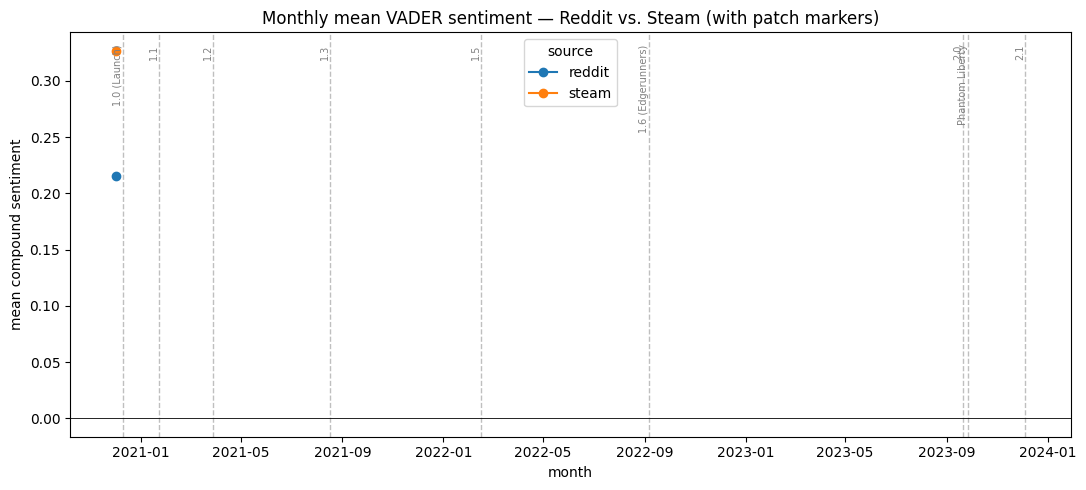

Wrote C:/Github/Data-Processing-2-/results/figures/sentiment_timeline.png and C:/Github/Data-Processing-2-/results/patch_overlay.csv


In [13]:
# -------------------------------------------------------------
# 5a · Sentiment time series + patch markers
#   -> results/figures/sentiment_timeline.png, results/patch_overlay.csv
# Loads the small monthly aggregate (pandas is safe here) and the patch
# timeline; plots both source curves with patch dates as vertical markers.
# `ts` is reused by 5b-5d below.
# -------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt

ts = pd.read_csv(RESULTS + "sentiment_timeseries.csv")
ts["month_dt"] = pd.to_datetime(ts["month"] + "-01")
ts = ts.sort_values(["source", "month_dt"]).reset_index(drop=True)

# Patch overlay table (subset of the patch timeline) for the figure.
patches_pd = pd.read_csv(PATCH_TIMELINE)[["patch_name", "release_date"]]
patches_pd["release_date"] = pd.to_datetime(patches_pd["release_date"])
patches_pd = patches_pd[
    patches_pd["release_date"].between(WINDOW_START, WINDOW_END)
].sort_values("release_date").reset_index(drop=True)
patches_pd.to_csv(RESULTS + "patch_overlay.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
for src, grp in ts.groupby("source"):
    ax.plot(grp["month_dt"], grp["mean_sentiment"], marker="o", label=src)
top = ax.get_ylim()[1]
for _, p in patches_pd.iterrows():
    ax.axvline(p["release_date"], color="grey", linestyle="--", alpha=0.5, linewidth=1)
    ax.text(p["release_date"], top, p["patch_name"], rotation=90,
            va="top", ha="right", fontsize=7, color="grey")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Monthly mean VADER sentiment — Reddit vs. Steam (with patch markers)")
ax.set_xlabel("month"); ax.set_ylabel("mean compound sentiment")
ax.legend(title="source")
fig.tight_layout()
fig.savefig(FIGURES + "sentiment_timeline.png", dpi=150)
plt.show()
print("Wrote", FIGURES + "sentiment_timeline.png", "and", RESULTS + "patch_overlay.csv")

### 5b · Review-Bombing / Volume Anomaly Flag

Review-bombing shows up as an abnormal **spike in volume**. Within each source we z-score the
monthly document count and flag months above `ANOMALY_Z_THRESHOLD`. These flags feed the
robustness check in 5c. → `results/anomaly_flags.csv`

In [14]:
# -------------------------------------------------------------
# 5b · Volume anomaly / review-bombing flag -> results/anomaly_flags.csv
# Within each source, z-score the monthly document count n. A spike
# (z > ANOMALY_Z_THRESHOLD) flags a month of unusual activity (e.g. brigading
# or review-bombing). Population std (ddof=0); single-month groups -> z=0.
# -------------------------------------------------------------
def _zscore(s):
    sd = s.std(ddof=0)
    return (s - s.mean()) / sd if sd and len(s) > 1 else pd.Series(0.0, index=s.index)

an = ts[["source", "month", "n"]].copy()
an["z"] = an.groupby("source")["n"].transform(_zscore).round(3)
an["is_anomaly"] = an["z"] > ANOMALY_Z_THRESHOLD
an.to_csv(RESULTS + "anomaly_flags.csv", index=False)
print("Wrote", RESULTS + "anomaly_flags.csv",
      f"({int(an['is_anomaly'].sum())} month(s) flagged)")
an[an["is_anomaly"]]

Wrote C:/Github/Data-Processing-2-/results/anomaly_flags.csv (0 month(s) flagged)


,source,month,n,z,is_anomaly


### 5c · Sentiment Excluding Bombing Windows

Recompute the time series with the flagged high-volume months removed. This lets the report show
the sentiment trajectory **with and without** suspected review-bombing, as a robustness check on
the recovery thesis. → `results/sentiment_excl_bombing.csv`

In [15]:
# -------------------------------------------------------------
# 5c · Sentiment excluding flagged (bombing) months -> results/sentiment_excl_bombing.csv
# Robustness: re-report the time series with anomalous-volume months removed,
# so the report can show sentiment "with vs. without" suspected review-bombing.
# -------------------------------------------------------------
flags = pd.read_csv(RESULTS + "anomaly_flags.csv")
flagged = set(zip(flags.loc[flags["is_anomaly"], "source"],
                  flags.loc[flags["is_anomaly"], "month"]))

excl = ts[~ts.apply(lambda r: (r["source"], r["month"]) in flagged, axis=1)]
excl[["source", "month", "n", "mean_sentiment", "std_sentiment"]].to_csv(
    RESULTS + "sentiment_excl_bombing.csv", index=False)
print("Wrote", RESULTS + "sentiment_excl_bombing.csv",
      f"({len(ts) - len(excl)} month(s) removed)")
excl[["source", "month", "n", "mean_sentiment"]]

Wrote C:/Github/Data-Processing-2-/results/sentiment_excl_bombing.csv (0 month(s) removed)


,source,month,n,mean_sentiment
0,reddit,2020-12,28654,0.2154
1,steam,2020-12,1819,0.3269


### 5d · Recovery Metric — Core Thesis

The project's central claim is that **Reddit sentiment recovers faster than Steam** after the
launch crisis. We operationalize "recovery" as: the first month *after* each source's sentiment
**trough** in which the monthly mean returns to `RECOVERY_TARGET` (≥ 0, i.e. non-negative).
`recovery_days` is the distance from trough to that month — smaller = faster recovery.
→ `results/recovery_metric.csv`

In [16]:
# -------------------------------------------------------------
# 5d · Recovery metric (CORE THESIS) -> results/recovery_metric.csv
# Per source: locate the sentiment trough, then the first later month whose mean
# returns to >= RECOVERY_TARGET (neutral). recovery_days = gap between the two
# month-starts. Comparing recovery_days across sources tests the thesis.
# -------------------------------------------------------------
RECOVERY_TARGET = 0.0   # "recovered" = monthly mean compound sentiment back to non-negative

rows = []
for src, grp in ts.sort_values("month_dt").groupby("source"):
    g = grp.reset_index(drop=True)
    i_tr = int(g["mean_sentiment"].idxmin())
    after = g.loc[i_tr + 1:]
    rec = after[after["mean_sentiment"] >= RECOVERY_TARGET].head(1)
    if len(rec):
        recovery_month = rec.iloc[0]["month"]
        recovery_days = int((rec.iloc[0]["month_dt"] - g.loc[i_tr, "month_dt"]).days)
    else:
        recovery_month, recovery_days = None, None   # no recovery within the window
    rows.append({"source": src,
                 "trough_month": g.loc[i_tr, "month"],
                 "trough_sentiment": round(float(g.loc[i_tr, "mean_sentiment"]), 4),
                 "recovery_month": recovery_month,
                 "recovery_days": recovery_days})

recovery = pd.DataFrame(rows)
recovery.to_csv(RESULTS + "recovery_metric.csv", index=False)
print("Wrote", RESULTS + "recovery_metric.csv")
recovery

Wrote C:/Github/Data-Processing-2-/results/recovery_metric.csv


,source,trough_month,trough_sentiment,recovery_month,recovery_days
0,reddit,2020-12,0.2154,None,None
1,steam,2020-12,0.3269,None,None


### 5e · Topic Analysis (LDA)

What are people talking about? We tokenize the scored corpus (lowercased here, separate from the
case-sensitive VADER path), drop English + domain stopwords, vectorize term counts, and fit an
**LDA** with `LDA_NUM_TOPICS` topics and a fixed `seed=SEED` (reproducible). Output: the top terms
per topic. `weight` is the summed probability of a topic's top-10 terms (a rough concentration
measure). → `results/topics.csv`

In [17]:
# -------------------------------------------------------------
# 5e · Topic analysis (LDA) -> results/topics.csv
# Lowercase tokenize (separate from VADER), drop stopwords, CountVectorizer,
# then LDA with a fixed seed for reproducibility. We report the top terms per topic.
# -------------------------------------------------------------
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, CountVectorizer
from pyspark.ml.clustering import LDA
import pandas as pd

docs = spark.read.parquet(PROCESSED + "scored/").select("text")

tok = RegexTokenizer(inputCol="text", outputCol="tok",
                     pattern=r"[^A-Za-z]+", toLowercase=True, minTokenLength=3)
extra_stop = ["game", "games", "like", "really", "get", "got", "one", "even", "would",
              "cyberpunk", "play", "played", "playing", "dont", "im", "youre", "thing"]
sw = StopWordsRemover(inputCol="tok", outputCol="terms",
                      stopWords=StopWordsRemover.loadDefaultStopWords("english") + extra_stop)
cv = CountVectorizer(inputCol="terms", outputCol="tf", vocabSize=5000, minDF=5.0)

terms_df = sw.transform(tok.transform(docs))
cv_model = cv.fit(terms_df)
tf = cv_model.transform(terms_df).select("tf")

lda = LDA(k=LDA_NUM_TOPICS, maxIter=10, seed=SEED, featuresCol="tf", optimizer="online")
lda_model = lda.fit(tf)

vocab = cv_model.vocabulary
rows = []
for r in lda_model.describeTopics(10).collect():
    words = [vocab[i] for i in r["termIndices"]]
    rows.append({"topic_id": int(r["topic"]),
                 "top_terms": ", ".join(words),
                 "weight": round(float(sum(r["termWeights"])), 4)})
topics_pd = pd.DataFrame(rows)
topics_pd.to_csv(RESULTS + "topics.csv", index=False)
print("Wrote", RESULTS + "topics.csv")
topics_pd

Wrote C:/Github/Data-Processing-2-/results/topics.csv


,topic_id,top_terms,weight
0,0,"removed, pre, steam, xbox, buy, questions, rel...",0.0825
1,1,"que, jogo, com, tem, para, uma, mais, pra, mas...",0.0675
2,2,"removed, good, also, need, people, anyone, kno...",0.0622
3,3,"boss, bigg, time, mode, good, rahul, want, pho...",0.0315
4,4,"story, best, good, first, character, new, time...",0.0505
5,5,"corpo, street, city, removed, kid, nomad, know...",0.0509
6,6,"deleted, removed, question, post, time, settin...",0.0740
7,7,"people, time, much, think, want, still, see, w...",0.0574
